# **AI assignment for Discrete Bayesian Network**

In [2]:
!pip install pgmpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 53.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 756.0/756.0 kB 35.9 MB/s eta 0:00:00


In [3]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
from pgmpy.estimators import BayesianEstimator
from pgmpy.sampling import BayesianModelSampling
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [4]:
student_model = DiscreteBayesianNetwork([
    ('CGPA', 'WT'),
    ('TS', 'WT'),
    ('TS', 'I'),
    ('SS', 'I'),
    ('WT', 'JO'),
    ('I', 'JO')
])



In [5]:
# P(CGPA)
cgpa_cpd = TabularCPD(variable='CGPA', variable_card=3,
                      values=[[0.2],[0.5],[0.3]],
                      state_names={'CGPA': ['Low', 'Medium', 'High']})

# P(TS)
ts_cpd = TabularCPD(variable='TS', variable_card=2,
                      values=[[0.4],[0.6]],
                      state_names={'TS': ['Weak', 'Strong']})

# P(SS)
ss_cpd = TabularCPD(variable='SS', variable_card=2,
                      values=[[0.5],[0.5]],
                      state_names={'SS': ['Weak', 'Strong']})

# P(WT| CGPA, TS)
wt_cpd = TabularCPD(variable = 'WT' , variable_card =2 ,
                        values =[[0.8 , 0.6 , 0.3 , 0.4 , 0.2 , 0.1] ,
                                 [0.2 , 0.4 , 0.7 , 0.6 , 0.8 , 0.9]] ,
                        evidence =[ 'CGPA' , 'TS'] , evidence_card =[3 , 2] ,
                        state_names ={ 'WT': [ 'Fail' , 'Pass'] ,
                                        'CGPA': [ 'Low' , 'Medium' , 'High'] ,
                                        'TS': [ 'Weak' , 'Strong' ]})

# P(I | TS, SS)
i_cpd = TabularCPD(variable = 'I' , variable_card =2 ,
                        values =[[0.7 , 0.4 , 0.3 , 0.1] ,
                                 [0.3 , 0.6 , 0.7 , 0.9]] ,
                        evidence =[ 'TS' , 'SS'] , evidence_card =[2 , 2] ,
                        state_names ={ 'I': [ 'Fail' , 'Pass'] ,
                                        'TS': [ 'Weak' , 'Strong'] ,
                                        'SS': [ 'Weak' , 'Strong' ]})

# P(JO| WT, I)
jo_cpd = TabularCPD(variable = 'JO' , variable_card =2 ,
                        values =[[0.99 , 0.8 , 0.6 , 0.1] ,
                                 [0.01 , 0.2 , 0.4 , 0.9]] ,
                        evidence =[ 'WT' , 'I'] , evidence_card =[2 , 2] ,
                        state_names ={ 'JO': [ 'No' , 'Yes'] ,
                                        'WT': [ 'Fail' , 'Pass'] ,
                                        'I': [ 'Fail' , 'Pass' ]})

student_model.add_cpds(cgpa_cpd, ts_cpd, ss_cpd, wt_cpd, i_cpd, jo_cpd)



print("Model check:", student_model.check_model())



Model check: True


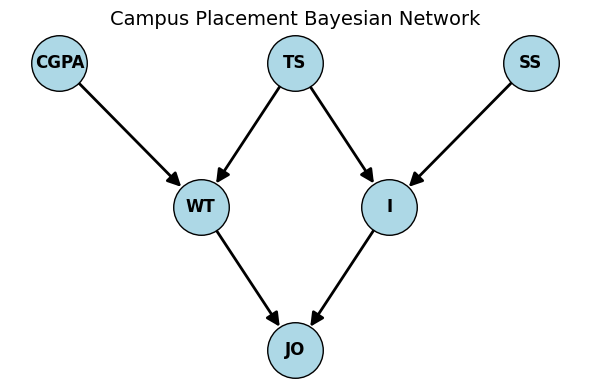

In [6]:
graph = nx.DiGraph()
graph.add_edges_from([
    ('CGPA', 'WT'),
    ('TS', 'WT'),
    ('TS', 'I'),
    ('SS', 'I'),
    ('WT', 'JO'),
    ('I', 'JO')
])

# Define positions for a  diagram
pos = {
    'CGPA': (0, 3),
    'TS': (5, 3),
    'SS': (10, 3),
    'WT': (3, 2),
    'I': (7, 2),
    'JO': (5, 1)
}

#  Draw the directed graph
plt.figure(figsize=(6, 4))
nx.draw_networkx_nodes(graph, pos, node_color='lightblue', node_size=1600, edgecolors='black')
nx.draw_networkx_labels(graph, pos, font_size=12, font_weight='bold')

# Add 'node_size=1600' here to make the arrows visible.
nx.draw_networkx_edges(
    graph,
    pos,
    arrows=True,
    arrowstyle='-|>',
    arrowsize=20,
    width=2,
    node_size=1600
)
plt.title("Campus Placement Bayesian Network", fontsize=14)
plt.axis('off')
plt.tight_layout()
plt.show()



In [7]:
infer = VariableElimination(student_model)

print("Overall Job Offer Probability:")
query_1 = infer.query(variables=['JO'])
print(query_1)

print("Probability of getting job offer after having High CGPA and Strong Technical Skills:")
query_2 = infer.query(variables=['JO'], evidence={'CGPA': 'High', 'TS': 'Strong'})
print(query_2)

print("Probability of having Strong Technical Skills after having Job Offer:")
query_3 = infer.query(variables=['TS'], evidence={'JO': 'Yes'}).get_value(TS='Strong')
print(query_3)

print("Probability of having passed Written Test after having Job Offer:")
query_4 = infer.query(variables=['WT'], evidence={'JO': 'Yes'}).get_value(WT='Pass')
print(query_4)

print("Probability of having passed Written Test after having Job Offer and having passed Interview:")
query_5 = infer.query(variables=['WT'], evidence={'JO': 'Yes', 'I': 'Pass'}).get_value(WT='Pass')
print(query_5)



Overall Job Offer Probability:
+---------+-----------+
| JO      |   phi(JO) |
+=========+===========+
| JO(No)  |    0.4823 |
+---------+-----------+
| JO(Yes) |    0.5177 |
+---------+-----------+
Probability of getting job offer after having High CGPA and Strong Technical Skills:
+---------+-----------+
| JO      |   phi(JO) |
+=========+===========+
| JO(No)  |    0.2638 |
+---------+-----------+
| JO(Yes) |    0.7362 |
+---------+-----------+
Probability of having Strong Technical Skills after having Job Offer:
0.668438764116572
Probability of having passed Written Test after having Job Offer:
0.9069764746336355
Probability of having passed Written Test after having Job Offer and having passed Interview:
0.890827865419517


Here we can see that the last two probabilities changed


In [8]:
print("\n Generating 20,000 Data Samples ---")

#  Set up the sampler
sampler = BayesianModelSampling(student_model)

#  Generate the data
data = sampler.forward_sample(size=20000)

print("Data generated. Here are the first 5 rows:")
print(data.head())


print("\n Learning Parameters from Data ---")

#  Create a new, "empty" model with only the structure
# This model doesn't know any of the probabilities yet.


model_to_learn = DiscreteBayesianNetwork(student_model.edges())

# "Train" the model on the data.
# The .fit() method calculates all the conditional probabilities from the data.

model_to_learn.fit(data, estimator=BayesianEstimator)

print("Model has been 'fit' to the data.")




 Generating 20,000 Data Samples ---


  0%|          | 0/6 [00:00<?, ?it/s]

Data generated. Here are the first 5 rows:
     CGPA    WT      TS     I      SS   JO
0     Low  Fail    Weak  Fail    Weak   No
1  Medium  Pass  Strong  Pass  Strong  Yes
2  Medium  Pass    Weak  Fail    Weak  Yes
3    High  Fail    Weak  Pass  Strong   No
4     Low  Pass  Strong  Pass  Strong  Yes

 Learning Parameters from Data ---
Model has been 'fit' to the data.


In [12]:
print("\n--- PART 4: Comparing original vs. Learned")

#  Compare P(JO)
print("\nJob Offer CPD ")
print("Original P(JO):")
print(student_model.get_cpds('JO')) # This was correct
print("Learned P(JO):")
print(model_to_learn.get_cpds('JO')) # This was correct




--- PART 4: Comparing original vs. Learned

Job Offer CPD 
Original P(JO):
+---------+----------+----------+----------+----------+
| WT      | WT(Fail) | WT(Fail) | WT(Pass) | WT(Pass) |
+---------+----------+----------+----------+----------+
| I       | I(Fail)  | I(Pass)  | I(Fail)  | I(Pass)  |
+---------+----------+----------+----------+----------+
| JO(No)  | 0.99     | 0.8      | 0.6      | 0.1      |
+---------+----------+----------+----------+----------+
| JO(Yes) | 0.01     | 0.2      | 0.4      | 0.9      |
+---------+----------+----------+----------+----------+
Learned P(JO):
+---------+----------------------+-----+--------------------+
| I       | I(Fail)              | ... | I(Pass)            |
+---------+----------------------+-----+--------------------+
| WT      | WT(Fail)             | ... | WT(Pass)           |
+---------+----------------------+-----+--------------------+
| JO(No)  | 0.9886840757808499   | ... | 0.0999762420930716 |
+---------+----------------------

Here we can see that the table values are almost equal